In [1]:
import torch
from torchvision import transforms
from torch.utils.data import DataLoader
import wandb
torch.backends.cudnn.benchmark = True

In [2]:
import torchvision.models.detection as models
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = models.fasterrcnn_resnet50_fpn(weights)
transform = weights.transforms()

f:\deps\python\Lib\site-packages\torchvision\models\_utils.py:135: UserWarning: Using 'weights' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(


In [3]:
from torchvision.datasets import VOCDetection
from torch.utils.data import Dataset
from torchvision.transforms import v2
from torch import tensor
# mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
# std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

# train_transform = transforms.Compose([
#     transforms.RandomResizedCrop(224, scale=(0.8,1.0)),
#     transforms.RandomHorizontalFlip(),
#     transforms.ColorJitter(
#         brightness=0.2,
#         contrast=0.2,
#         saturation=0.2,
#         hue=0.1
#     ),
#     transforms.RandomPerspective(
#     distortion_scale=0.2,
#     p=0.3
# ),
#     transforms.ToTensor(),
#     transforms.Normalize(mean, std),
#     transforms.RandomErasing(
#         p=0.25,
#         scale=(0.02,0.15),
#         ratio=(0.3,3.3)
#     )
# ])

# test_transform = transforms.Compose([
#     transforms.Resize(256),
#     transforms.CenterCrop(224),
#     transforms.ToTensor(),
#     transforms.Normalize(mean, std),
# ])
def collate_fn(batch):
    return tuple(zip(*batch))

class VOCDataSet(Dataset):
    def __init__(self, root, year, image_set, transform=None) -> None:
        self.dataset = VOCDetection(
            root=root,
            year=year,
            image_set=image_set,
            download=True,
        )
        self.transform = transform
    
    def __len__(self):
        return len(self.dataset)

    VOC_CLASSES = {
        "__background__": 0,
        "aeroplane": 1,
        "bicycle": 2,
        "bird": 3,
        "boat": 4,
        "bottle": 5,
        "bus": 6,
        "car": 7,
        "cat": 8,
        "chair": 9,
        "cow": 10,
        "diningtable": 11,
        "dog": 12,
        "horse": 13,
        "motorbike": 14,
        "person": 15,
        "pottedplant": 16,
        "sheep": 17,
        "sofa": 18,
        "train": 19,
        "tvmonitor": 20,
    }

    def __getitem__(self, index):
        image, annotation = self.dataset[index]

        if self.transform is not None:
            image = self.transform(image)
        
        objects = annotation["annotation"]["object"]

        if not isinstance(objects, list):
            objects = [objects]
        
        boxes = []
        labels = []
        area = []
        iscrowd = []
        for obj in objects:
            bbox = obj["bndbox"]
            xmin = float(bbox["xmin"])
            ymin = float(bbox["ymin"])
            xmax = float(bbox["xmax"])
            ymax = float(bbox["ymax"])
            boxes.append([xmin,ymin,xmax,ymax])
            area.append((xmax - xmin) * (ymax - ymin))

            labels.append(self.VOC_CLASSES[obj["name"]])
            
            iscrowd.append(0)


        target = {
            "boxes": tensor(boxes, dtype=torch.float32),
            "labels": tensor(labels, dtype=torch.int64),
            "image_id": tensor([index], dtype=torch.int64),
            "area": tensor(area, dtype=torch.float32),
            "iscrowd": tensor(iscrowd, dtype=torch.int64)
        }
        return image, target
    

train_dataset = VOCDataSet(
    root="./data",
    year="2012",
    image_set="train",
    transform=transform
)   

image, annotation = train_dataset[0]
print(image.shape)
print(annotation)
test_dataset = VOCDataSet(
    root="./data",
    year="2012",
    image_set="val",
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    collate_fn=collate_fn,
)

torch.Size([3, 442, 500])
{'boxes': tensor([[ 53.,  87., 471., 420.],
        [158.,  44., 289., 167.]]), 'labels': tensor([13, 15]), 'image_id': tensor([0]), 'area': tensor([139194.,  16113.]), 'iscrowd': tensor([0, 0])}


Sample from the training dataset

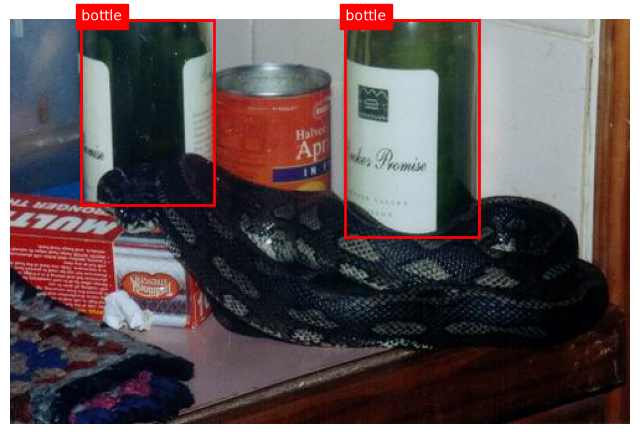

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

INV_VOC_CLASSES = {v: k for k, v in VOCDataSet.VOC_CLASSES.items()}

def show_sample(image, target):
    image = image.permute(1,2,0).numpy()

    fig, ax = plt.subplots(figsize=(8,8))
    ax.imshow(image)

    for box, label in zip(target["boxes"], target["labels"]):

        xmin, ymin, xmax, ymax = box.tolist()

        rect = patches.Rectangle(
            (xmin,ymin),
            xmax-xmin,
            ymax-ymin,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            ymin,
            INV_VOC_CLASSES[label.item()],
            color="white",
            backgroundcolor="red"
        )

    plt.axis("off")
    plt.show()

image, target = train_dataset[1]
show_sample(image, target)

In [5]:
run = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="shehryar11w-private",
    # Set the wandb project where this run will be logged.
    project="pascal-voc",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 1e-3,
        "architecture": "Faster-RCNN Progressive Unfreezing",
        "dataset": "pascal-voc",
        "epochs": 15,
    },
)


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\shehr\_netrc.
wandb: Currently logged in as: shehryar11w (shehryar11w-private) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

num_classes = 21   # VOC classes + background

for param in model.backbone.parameters():
    param.requires_grad = False
    
in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
device

device(type='cuda')

In [8]:
import torch.optim as optim

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-5
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15,
    eta_min=1e-6
)
scaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))

This covers the entire test-train loop over 15 epochs:
- **Progressive Unfreezing**: Unlock last layer after 5 epochs and entire network after 10 epochs

In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

metric = MeanAveragePrecision(iou_type="bbox")
best_map = 0.0
for epoch in range(15):  # loop over the dataset multiple times

    #Progressive Unfreezing
    if epoch == 5: # Epoch 6: unfreeze layer4
        print("Unfreezing layer4")

        for param in model.backbone.body.layer4.parameters():
            param.requires_grad = True

        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=1e-4,
            weight_decay=1e-4
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=5,
            eta_min=1e-6
        )

    if epoch == 10:  # Epoch 11: unfreeze everything
        print("Unfreezing entire network")

        for param in model.parameters():
            param.requires_grad = True

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=1e-5,
            weight_decay=1e-4
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=5,
            eta_min=1e-7
        )


    ### Train
    model.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        # zero the parameter gradients
        optimizer.zero_grad()

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            loss_dict = model(images, targets)

        # forward + backward + optimize using scaler
        loss = sum(loss for loss in loss_dict.values())
        
        running_loss += loss.item()
        
        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

    epoch_loss = running_loss / len(train_loader)

    print(f'[{epoch + 1}] Train loss: {epoch_loss:.4f}')

    ### Validate
    model.eval()
    metric.reset()

    with torch.no_grad():
        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            for images, targets in test_loader:

                images = [img.to(device) for img in images]
                targets = [
                    {k: v.to(device) for k, v in t.items()}
                    for t in targets
                ]

                predictions = model(images)

                metric.update(predictions, targets)

    results = metric.compute()

    print(
        f"Epoch {epoch+1}: "
        f"mAP={results['map']:.4f}, "
        f"mAP@50={results['map_50']:.4f}, "
        f"mAP@75={results['map_75']:.4f}"
    )

    wandb.log({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "map": results["map"].item(),
        "map_50": results["map_50"].item(),
        "map_75": results["map_75"].item(),
        "lr": scheduler.get_last_lr()[0],
    })

    scheduler.step()
    
    if results["map"] > best_map:
        best_map = results["map"]
        torch.save(model.state_dict(), "best_fasterrcnn.pth")

print('Finished Training')

In [ ]:
wandb.finish()

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
lr,███▇▇▂▂▁▁▁▁▁▁▁▁
train_loss,█▅▅▄▄▄▃▂▂▁▁▁▁▁▁
val_accuracy,▁▂▃▄▄▆▇▇█▇█████
val_loss,█▇▆▆▆▂▂▁▁▁▁▁▁▁▁
epoch,15
lr,0.0
train_loss,0.48153
val_accuracy,94.2
val_loss,0.56527
